# 03 · Pairs trading on four economically linked pairs

**Question:** if four pairs of related assets are chosen in advance and their spread is traded only while a cointegration test supports it, does the strategy earn anything after costs?

**Short answer:** no. Over 19 years the four-pair portfolio has a Sharpe of 0.00 after 5 bps of costs (95% interval about −0.43 to +0.46). The more informative result is how rarely it trades: each pair passes the Engle-Granger test on a one-year window only 7% to 11% of the time, close to the 5% that two unrelated random walks would pass by chance, and the portfolio has a trade open on fewer than 10% of the days. There are 33 trades in total and more than half of them end because the pair stops passing the test, not because the spread converged.

Rules of this notebook:
- It only imports from `backtester` and presents results; the logic lives in `src/` with its tests.
- The pairs and every parameter were fixed **before** looking at any result, and the backtest was run once. No pair, threshold or window was tried and discarded.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from backtester import ProportionalCosts, run_backtest
from backtester.data import load_prices, quality_report
from backtester.metrics import sharpe
from backtester.report import compare
from backtester.significance import bootstrap_sharpe, holm_adjust
from backtester.strategies import PairsTrading
from backtester.strategy import EqualWeight

PAIRS = [("KO", "PEP"), ("XOM", "CVX"), ("GLD", "GDX"), ("EWA", "EWC")]
TICKERS = [ticker for pair in PAIRS for ticker in pair]
START, END = "2006-05-22", "2026-10-31"  # GDX starts trading on 2006-05-22; fixed end date
COSTS_BPS = 5
COMBINED = "All pairs"
IMG_DIR = Path("../docs/img")

## 1. The pairs

| Pair (y / x) | Why the two prices should be tied together |
|---|---|
| **KO / PEP** | The two dominant soft-drink companies: same consumers, same input costs. |
| **XOM / CVX** | US integrated oil majors, both driven by crude prices and refining margins. |
| **GLD / GDX** | Gold and gold miners, whose revenue is the gold price. |
| **EWA / EWC** | Australia and Canada, two commodity-exporting economies. |

The pairs were chosen by economic reasoning, not by scanning many candidates for the best statistical fit, which would be data mining. But they are also the textbook examples of pairs trading, and they are textbook examples partly because they worked in earlier samples. The choice is therefore not free of selection bias, and that bias works in favour of the strategy.

The sample starts when GDX starts trading (May 2006). Prices are adjusted closes from Yahoo Finance, with dividends reinvested.

In [2]:
prices = load_prices(TICKERS, start=START, end=END)
print(f"{prices.shape[0]} sessions, from {prices.index[0].date()} to {prices.index[-1].date()}")
quality_report(prices)

5144 sessions, from 2006-05-22 to 2026-10-30


,First date,Last date,Observations,Internal NaNs,Non-positive prices,Largest |daily return|,Largest gap (days)
CVX,2006-05-22,2026-10-30,5144,0,0,0.227407,5
EWA,2006-05-22,2026-10-30,5144,0,0,0.207495,5
EWC,2006-05-22,2026-10-30,5144,0,0,0.133219,5
GDX,2006-05-22,2026-10-30,5144,0,0,0.265385,5
GLD,2006-05-22,2026-10-30,5144,0,0,0.112905,5
KO,2006-05-22,2026-10-30,5144,0,0,0.138795,5
PEP,2006-05-22,2026-10-30,5144,0,0,0.129366,5
XOM,2006-05-22,2026-10-30,5144,0,0,0.171905,5


## 2. The strategy

For each pair (y, x), every 21 sessions and using only the last 252 closes:

1. **Hedge ratio.** OLS of log(y) on log(x) with an intercept. The spread is log(y) − α − β·log(x).
2. **Cointegration test.** Engle-Granger test on that same window. The pair is *tradable* for the next 21 sessions if the p-value is below 0.05 and β is positive.
3. **Z-score.** The spread divided by its standard deviation in the window. α, β and that standard deviation stay frozen until the next re-estimation.

| Rule | Value |
|---|---|
| Enter against the spread | \|z\| > 2 (short the spread if z > 0, long if z < 0) |
| Exit | \|z\| < 0.5, or the spread crosses zero |
| Stop-loss | z moves beyond 4 against the trade |
| Maximum holding period | 63 sessions |
| After a stop or a time-out | no new entry until \|z\| < 0.5 |
| The pair stops being tradable | any open trade is closed |

Long the spread is long y and short x, with the two legs in proportion 1 : β. The gross exposure is 1 whenever at least one pair has a trade open, shared equally among the pairs with an open trade, and 0 otherwise.

**No look-ahead.** The hedge ratio, the test and the z-score of day *t* use prices up to the close of *t*, and the engine applies the decision to the return of *t+1*. The re-estimation dates are counted from the first row, so they do not depend on where the sample ends. `tests/test_pairs_trading.py` checks that changing future prices leaves past weights unchanged.

**Execution and costs.** 5 bps per unit of turnover, as in the other notebooks. The strategy only gives an order when its target changes (an entry, an exit, or a new hedge ratio for an open trade); in between, the two legs drift. Not modelled: the cost of borrowing the short leg, and interest on cash (the engine pays 0%).

Each pair is also run on its own, with a gross exposure of 1 while its trade is open, to see where the combined result comes from. Everything is measured from the first day a signal is possible (one year after the start).

In [3]:
strategies = {f"{y}/{x}": PairsTrading([(y, x)]) for y, x in PAIRS}
strategies[COMBINED] = PairsTrading(PAIRS)
combined = strategies[COMBINED]
costs = ProportionalCosts(bps=COSTS_BPS)

start = prices.index[combined.formation - 1]  # first close with a full formation window
results = {name: run_backtest(prices, s, costs).since(start) for name, s in strategies.items()}
print(f"Period: {start.date()} to {prices.index[-1].date()}")

Period: 2007-05-22 to 2026-10-30


## 3. How often is each pair tradable?

In [4]:
tradable = combined.tradable(prices).loc[start:]
in_trade = combined.positions(prices).loc[start:] != 0
trades = combined.trades(prices)

activity = pd.DataFrame(
    {
        "Share of days tradable": tradable.mean(),
        "Share of days in a trade": in_trade.mean(),
        "Trades": trades.groupby("pair").size(),
        "Average days held": trades.groupby("pair")["days"].mean(),
    }
)
print(f"Days with at least one trade open: {in_trade.any(axis=1).mean():.1%}")
print(f"Days with more than one trade open: {(in_trade.sum(axis=1) > 1).mean():.1%}")
activity.round(3)

Days with at least one trade open: 9.6%
Days with more than one trade open: 0.1%


,Share of days tradable,Share of days in a trade,Trades,Average days held
EWA/EWC,0.090,0.019,7,13.143
GLD/GDX,0.112,0.031,11,13.909
KO/PEP,0.073,0.029,7,20.429
XOM/CVX,0.077,0.018,8,10.875


Share of days of each year on which each pair was tradable:

In [5]:
tradable.groupby(tradable.index.year).mean().round(2)

,KO/PEP,XOM/CVX,GLD/GDX,EWA/EWC
Date,,,,
2007,0.27,0.73,0.00,0.05
2008,0.00,0.38,0.04,0.05
2009,0.17,0.00,0.30,0.00
2010,0.00,0.00,0.12,0.00
2011,0.00,0.00,0.38,0.08
2012,0.00,0.08,0.25,0.00
2013,0.17,0.00,0.00,0.00
2014,0.19,0.08,0.25,0.00
2015,0.56,0.00,0.42,0.08


How the trades ended. `target` is the intended exit (the spread came back); `not_cointegrated` means a re-estimation stopped supporting the pair while the trade was open.

In [6]:
trades.groupby(["pair", "reason"]).size().unstack(fill_value=0).assign(
    Total=lambda table: table.sum(axis=1)
)

reason,not_cointegrated,stop,target,time,Total
pair,,,,,
EWA/EWC,5,0,2,0,7
GLD/GDX,6,1,4,0,11
KO/PEP,4,1,1,1,7
XOM/CVX,3,1,4,0,8


**Reading these tables**

- **The pairs are tradable 7% to 11% of the time.** A 5% test run on two unrelated random walks passes about 5% of the time by construction (`test_random_walk_pair_is_rarely_tradable` shows it on synthetic data). So the four pairs pass only a little more often than pairs with no relationship at all.
- **This does not prove that the pairs are not cointegrated.** The Engle-Granger test has low power on 252 observations when the spread reverts slowly: in the synthetic pair used in the tests, a spread with a half-life of about a week is detected in only about half of the 120-day windows. What the tables say is narrower: with a one-year window, this filter cannot tell these four pairs from unrelated ones most of the time.
- **Tradable periods do not persist.** There is no pair that is tradable for years; the periods are scattered and short (the best cases are XOM/CVX in 2007 and KO/PEP in 2015). 18 of the 33 trades are closed because the next re-estimation no longer supports the pair, against 11 that reach their target. A filter that switches on and off this quickly behaves more like noise than like the detection of a stable relationship.
- **The portfolio is in cash more than 90% of the time**, and almost never holds two pairs at once. "Gross exposure 1 across active pairs" therefore means, in practice, one pair at a time.

## 4. Equity

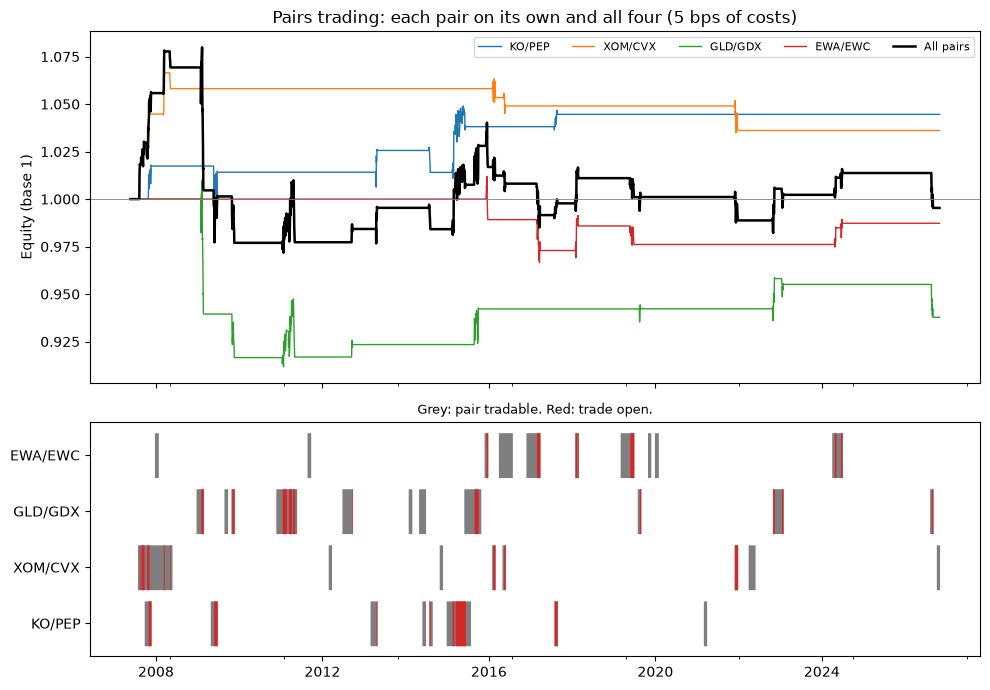

In [7]:
equity = pd.DataFrame({name: result.equity for name, result in results.items()})

fig, (ax_equity, ax_tradable) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]}
)
equity.drop(columns=COMBINED).plot(ax=ax_equity, lw=1)
equity[COMBINED].plot(ax=ax_equity, lw=1.8, color="black", label=COMBINED)
ax_equity.axhline(1.0, color="grey", lw=0.6)
ax_equity.set_ylabel("Equity (base 1)")
ax_equity.set_title(f"Pairs trading: each pair on its own and all four ({COSTS_BPS} bps of costs)")
ax_equity.legend(ncol=5, fontsize=8)

for row, pair in enumerate(tradable.columns):
    ax_tradable.fill_between(
        tradable.index, row, row + 0.8 * tradable[pair], step="post", color="tab:grey", lw=0
    )
    ax_tradable.fill_between(
        in_trade.index, row, row + 0.8 * in_trade[pair], step="post", color="tab:red", lw=0
    )
ax_tradable.set_yticks([row + 0.4 for row in range(len(tradable.columns))], tradable.columns)
ax_tradable.set_title("Grey: pair tradable. Red: trade open.", fontsize=9)
ax_tradable.set_xlabel("")
fig.tight_layout()
IMG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(IMG_DIR / "pairs_trading.png", dpi=150)
plt.show()

## 5. Metrics

The metrics are computed on every day of the period, including the days in cash. With a strategy that is idle more than 90% of the time, the annual return and volatility are small by construction; the Sharpe ratio is the figure that can be compared.

In [8]:
compare(results).round(4)

,KO/PEP,XOM/CVX,GLD/GDX,EWA/EWC,All pairs
CAGR,0.0023,0.0018,-0.0033,-0.0007,-0.0002
Annual volatility,0.0124,0.0089,0.0154,0.0075,0.0227
Sharpe,0.1880,0.2089,-0.2072,-0.0840,0.0008
Sortino,0.2849,0.3352,-0.2673,-0.1215,0.0011
Max drawdown,-0.0277,-0.0300,-0.0973,-0.0448,-0.1001
Calmar,0.0811,0.0609,-0.0340,-0.0147,-0.0024
Annual turnover,0.7327,0.8251,1.1634,0.7218,3.4444
Annual costs,0.0004,0.0004,0.0006,0.0004,0.0017


The Sharpe before costs, the average gross and net exposure, and the daily correlation with a monthly-rebalanced equal-weight portfolio of the same eight assets (shown only to check market neutrality):

In [9]:
equal_weight = run_backtest(prices, EqualWeight(), costs, rebalance="ME").since(start)
pd.DataFrame(
    {
        "Sharpe before costs": {name: sharpe(r.gross_returns) for name, r in results.items()},
        "Sharpe after costs": {name: sharpe(r.returns) for name, r in results.items()},
        "Average gross exposure": {
            name: r.weights.abs().sum(axis=1).mean() for name, r in results.items()
        },
        "Average net exposure": {name: r.weights.sum(axis=1).mean() for name, r in results.items()},
        "Correlation with equal weight": {
            name: r.returns.corr(equal_weight.returns) for name, r in results.items()
        },
    }
).round(3)

,Sharpe before costs,Sharpe after costs,Average gross exposure,Average net exposure,Correlation with equal weight
KO/PEP,0.218,0.188,0.029,0.004,0.006
XOM/CVX,0.255,0.209,0.018,-0.002,-0.002
GLD/GDX,-0.170,-0.207,0.032,-0.008,0.069
EWA/EWC,-0.036,-0.084,0.019,-0.001,-0.025
All pairs,0.077,0.001,0.097,-0.008,0.041


## 6. Year by year

In [10]:
by_year = pd.DataFrame(
    {name: (1 + r.returns).groupby(r.returns.index.year).prod() - 1 for name, r in results.items()}
)
by_year.round(3)

,KO/PEP,XOM/CVX,GLD/GDX,EWA/EWC,All pairs
Date,,,,,
2007,0.017,0.045,0.000,0.000,0.056
2008,0.000,0.013,0.000,0.000,0.013
2009,-0.003,0.000,-0.083,0.000,-0.086
2010,0.000,0.000,0.000,0.000,0.000
2011,0.000,0.000,0.000,0.000,0.000
2012,0.000,0.000,0.007,0.000,0.007
2013,0.011,0.000,0.000,0.000,0.011
2014,-0.011,0.000,0.000,0.000,-0.011
2015,0.024,0.000,0.020,-0.011,0.033


## 7. Is any Sharpe ratio different from zero?

**The benchmark is cash, not equal weight.** In notebooks 01 and 02 the strategies were long-only portfolios of the same assets as the benchmark, so the natural question was whether they beat holding those assets. Pairs trading is long one leg and short the other: its net exposure is about zero and its correlation with the equal-weight portfolio is below 0.1. Comparing it with a portfolio that carries the full market risk would mostly measure whether the market went up, which says nothing about the strategy. The alternative to running it is to do nothing, and in this engine doing nothing earns exactly 0. The hypothesis tested is therefore **Sharpe = 0**.

The test is the one-sample version of the stationary bootstrap used before (`bootstrap_sharpe`): the daily returns are resampled in random blocks, which keeps the long runs of zero-return days together with the bursts of activity. The paired test of the other notebooks cannot be used here, because a constant series of zeros has no Sharpe ratio.

Five Sharpe ratios are tested (four pairs and the portfolio), so the table also shows Holm-adjusted p-values.

The warnings under the next cell are expected: for the pairs that trade least, a few of the 10,000 resampled series (at most 7) contain only days in cash, have no Sharpe ratio and are dropped.

In [11]:
rows = {}
for name, result in results.items():
    boot = bootstrap_sharpe(result.returns, n_boot=10_000, seed=0)
    rows[name] = {
        "Sharpe": boot.estimate,
        "95% CI low": boot.ci_low,
        "95% CI high": boot.ci_high,
        "p-value": boot.p_value,
        "Mean block (days)": round(boot.block_length),
    }
tests = pd.DataFrame(rows).T
tests.insert(4, "p-value (Holm)", holm_adjust(tests["p-value"]))
tests.round(3)

C:\Users\pablo\AppData\Local\Temp\ipykernel_15944\177301992.py:3: UserWarning: 2 bootstrap replicates had a constant series and were dropped
  boot = bootstrap_sharpe(result.returns, n_boot=10_000, seed=0)


C:\Users\pablo\AppData\Local\Temp\ipykernel_15944\177301992.py:3: UserWarning: 7 bootstrap replicates had a constant series and were dropped
  boot = bootstrap_sharpe(result.returns, n_boot=10_000, seed=0)


C:\Users\pablo\AppData\Local\Temp\ipykernel_15944\177301992.py:3: UserWarning: 6 bootstrap replicates had a constant series and were dropped
  boot = bootstrap_sharpe(result.returns, n_boot=10_000, seed=0)


,Sharpe,95% CI low,95% CI high,p-value,p-value (Holm),Mean block (days)
KO/PEP,0.188,-0.083,0.444,0.166,0.829,61.0
XOM/CVX,0.209,-0.233,0.667,0.389,1.000,45.0
GLD/GDX,-0.207,-0.627,0.272,0.386,1.000,56.0
EWA/EWC,-0.084,-0.441,0.286,0.682,1.000,44.0
All pairs,0.001,-0.427,0.461,0.997,1.000,54.0


**Reading the result**

- **No Sharpe ratio is distinguishable from zero.** Zero is inside all five intervals. The smallest raw p-value is 0.17 (KO/PEP) and it becomes 0.83 after the Holm correction.
- **Two pairs are slightly positive and two slightly negative** (KO/PEP +0.19, XOM/CVX +0.21, GLD/GDX −0.21, EWA/EWC −0.08). That is what four draws around zero look like. Reporting KO/PEP or XOM/CVX alone as "pairs that work" would be picking winners after the fact.
- **The intervals are wide** (about ±0.45 for the portfolio) because the evidence is thin: 33 trades in 19 years. The data are compatible with a small positive edge and with a small negative one.

## 8. Interpretation

**Pairs trading on these four pairs, with a one-year Engle-Granger filter, earns nothing: it barely trades, and when it does the result is indistinguishable from zero.**

| | KO/PEP | XOM/CVX | GLD/GDX | EWA/EWC | All pairs |
|---|---|---|---|---|---|
| Share of days tradable | 7.3% | 7.7% | 11.2% | 9.0% | |
| Share of days in a trade | 2.9% | 1.8% | 3.1% | 1.9% | 9.6% |
| Trades | 7 | 8 | 11 | 7 | 33 |
| Sharpe before costs | 0.22 | 0.26 | −0.17 | −0.04 | 0.08 |
| Sharpe after costs | 0.19 | 0.21 | −0.21 | −0.08 | 0.00 |
| Max drawdown | −2.8% | −3.0% | −9.7% | −4.5% | −10.0% |
| Bootstrap p-value (raw / Holm) | 0.17 / 0.83 | 0.39 / 1.00 | 0.39 / 1.00 | 0.68 / 1.00 | 1.00 / 1.00 |

- **The filter is the main finding.** The economic story behind each pair is sound, but a statistical relationship that would justify trading the spread shows up in roughly one window out of ten, not much more than chance would give. The strategy as specified is mostly a decision not to trade.
- **GLD/GDX is the one clear loss**, and it is a known one. Miners are a leveraged and operationally risky claim on gold, not gold itself; the pair is tradable most often (11%) and loses most. In 2009 it lost 8.3% in a year in which the other pairs did almost nothing, which is most of the drawdown of the portfolio. The largest single loss (about 6%, January-February 2009) shows how: the hedge ratio estimated on the 2008 window was 0.24, so the "pair" was roughly 80% short gold against 20% long miners. That is close to an outright short position in gold, which kept rising. Legs weighted by β are only market-neutral while β is stable, and a window that contains a crash gives a β that is not.
- **Costs matter even at this low activity.** The portfolio's Sharpe goes from 0.08 before costs to 0.00 after 5 bps. A real implementation would also pay to borrow the short leg.
- **Most trades do not end by convergence.** 18 of 33 are closed because the pair stops passing the test. Closing in that case is a risk control, but it also means the typical trade is opened on a relationship that the same test rejects a few weeks later.

**Limitations**

- **Low power of the test.** A one-year window cannot detect slow mean reversion. A longer window would have more power and react more slowly to a relationship breaking down. Only one window (252) was run, as fixed in advance; nothing here says how the result changes with it.
- **Repeated testing.** The test is run about 230 times per pair at 5%. Some of the "tradable" periods are false positives, and nothing in the strategy corrects for that.
- **Thin evidence.** 33 trades. The bootstrap intervals reflect it, but a handful of trades (GLD/GDX in 2009) drive the totals.
- **Selection of the universe.** Four textbook pairs, chosen with knowledge that they are textbook pairs. If anything this favours the strategy, and it still shows nothing.
- **Costs and financing.** No borrow cost on the short leg, cash earns 0%, and the fills are at the close with 5 bps.
- **Fixed rules.** A hedge ratio from OLS in logs with frozen parameters between re-estimations. A Kalman filter, a total least squares hedge ratio or thresholds based on the spread's half-life are different strategies and would be new tests.

**Next steps**

- A sensitivity analysis over the formation window and the entry threshold (Phase 3), declared as such and with the number of variants accounted for.
- The Deflated Sharpe Ratio across everything tried in the project.
- A larger universe of candidate pairs with the selection done strictly out of sample (form on one period, trade on the next), which is the design of Gatev, Goetzmann and Rouwenhorst (2006).